**Data Import: US Census Data**

In [2]:
# install packages
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# file path to import data
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw'
processed_fldr = root_fldr / 'data' / 'processed'

In [4]:
# import Census data
raw_data_2024 = raw_fldr / 'ACS_2024_Income_Data.csv'
raw_data_2023 = raw_fldr / 'ACS_2023_Income_Data.csv'
raw_data_2022 = raw_fldr / 'ACS_2022_Income_Data.csv'
raw_data_2021 = raw_fldr / 'ACS_2021_Income_Data.csv'

In [5]:
census_2024 = pd.read_csv(raw_data_2024)
census_2023 = pd.read_csv(raw_data_2023)
census_2022 = pd.read_csv(raw_data_2022)
census_2021 = pd.read_csv(raw_data_2021)

In [5]:
# data dimensions
census_2024.shape

(1809, 5)

In [6]:
census_2023.shape

(1809, 5)

In [7]:
census_2022.shape

(1809, 5)

In [8]:
census_2021.shape

(1809, 5)

In [8]:
try:
    import pytidycensus as tc
except ImportError:
    %pip install pytidycensus[map]
    import pytidycensus as tc

In [9]:
tc.set_census_api_key("7c22dfdec9f14dbb40425508ecb5365141c535a3")

Census API key has been set for this session.


In [10]:
years = [2021, 2022, 2023, 2024]

us_income_data = pd.DataFrame()
for year in years:
    income_data = tc.get_acs(
        geography = "zcta",
        variables = "B19013_001",
        geometry = True,
        year = year)
    income_data['year'] = year
    us_income_data = pd.concat([us_income_data, income_data], ignore_index=True)

Getting data from the 2017-2021 5-year ACS


c:\Users\mis32\AppData\Local\miniforge3\envs\env700_gis\Lib\site-packages\pytidycensus\geography.py:101: UserWarning: Cartographic boundary files (cb=True) unavailable for year 2021. Falling back to detailed TIGER/Line files (cb=False). Original error: Cartographic boundary ZCTA files are only available for 2020. Use cb=False to get TIGER/Line ZCTAs f
  warnings.warn(warn_msg, UserWarning)


Getting data from the 2018-2022 5-year ACS


c:\Users\mis32\AppData\Local\miniforge3\envs\env700_gis\Lib\site-packages\pytidycensus\geography.py:101: UserWarning: Cartographic boundary files (cb=True) unavailable for year 2022. Falling back to detailed TIGER/Line files (cb=False). Original error: Cartographic boundary ZCTA files are only available for 2020. Use cb=False to get TIGER/Line ZCTAs f
  warnings.warn(warn_msg, UserWarning)


Getting data from the 2019-2023 5-year ACS


c:\Users\mis32\AppData\Local\miniforge3\envs\env700_gis\Lib\site-packages\pytidycensus\geography.py:101: UserWarning: Cartographic boundary files (cb=True) unavailable for year 2023. Falling back to detailed TIGER/Line files (cb=False). Original error: Cartographic boundary ZCTA files are only available for 2020. Use cb=False to get TIGER/Line ZCTAs f
  warnings.warn(warn_msg, UserWarning)


Getting data from the 2020-2024 5-year ACS


c:\Users\mis32\AppData\Local\miniforge3\envs\env700_gis\Lib\site-packages\pytidycensus\geography.py:101: UserWarning: Cartographic boundary files (cb=True) unavailable for year 2024. Falling back to detailed TIGER/Line files (cb=False). Original error: Cartographic boundary ZCTA files are only available for 2020. Use cb=False to get TIGER/Line ZCTAs f
  warnings.warn(warn_msg, UserWarning)


In [15]:
us_income_data.head()

,GEOID,geometry,ZCTA5CE20,GEOID20,B19013_001E,NAME,B19013_001_moe,year
0,47236,"POLYGON ((-85.7341 39.15597, -85.72749 39.1561...",47236,47236,113056,ZCTA5 47236,61897.0,2021
1,47870,"POLYGON ((-87.47414 39.37016, -87.47409 39.370...",47870,47870,<NA>,ZCTA5 47870,<NA>,2021
2,47851,"POLYGON ((-87.2477 39.57431, -87.2477 39.57441...",47851,47851,<NA>,ZCTA5 47851,<NA>,2021
3,47337,"POLYGON ((-85.44357 39.80328, -85.44346 39.803...",47337,47337,49583,ZCTA5 47337,28135.0,2021
4,47435,"POLYGON ((-86.29592 39.26547, -86.29592 39.266...",47435,47435,<NA>,ZCTA5 47435,<NA>,2021


In [21]:
us_income_data.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 135092 entries, 0 to 135091
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   GEOID           135092 non-null  str     
 1   geometry        135092 non-null  geometry
 2   ZCTA5CE20       135092 non-null  str     
 3   GEOID20         135092 non-null  str     
 4   B19013_001E     122447 non-null  object  
 5   NAME            135092 non-null  str     
 6   B19013_001_moe  122049 non-null  object  
 7   year            135092 non-null  int64   
dtypes: geometry(1), int64(1), object(2), str(4)
memory usage: 11.7+ MB


In [ ]:
us_income_data.rename(columns = {'B19013_001E': 'median_income',
                                 'NAME':'ZCTA'})


In [13]:
# Use processed data to filter down to CA ZCTAs 
ca_processed_data = processed_fldr / 'Income_2021_2024.csv'
ca_processed = pd.read_csv(ca_processed_data)

In [26]:
ca_zip_codes = ca_processed['zcta'].unique().astype(str).tolist()

In [27]:
ca_shapefile = us_income_data.loc[us_income_data['GEOID'].isin(ca_zip_codes)]

In [28]:
ca_shapefile.shape

(6432, 8)

In [29]:
ca_shapefile.head()

,GEOID,geometry,ZCTA5CE20,GEOID20,B19013_001E,NAME,B19013_001_moe,year
28188,94587,"POLYGON ((-122.15501 37.59111, -122.15242 37.5...",94587,94587,127828,ZCTA5 94587,4291.0,2021
28189,95126,"POLYGON ((-121.93753 37.33737, -121.93743 37.3...",95126,95126,116063,ZCTA5 95126,10998.0,2021
28190,90602,"POLYGON ((-118.05285 33.95686, -118.05223 33.9...",90602,90602,55328,ZCTA5 90602,5300.0,2021
28191,95130,"POLYGON ((-121.99455 37.28948, -121.99436 37.2...",95130,95130,158656,ZCTA5 95130,19405.0,2021
28192,95035,"POLYGON ((-121.9311 37.41998, -121.93105 37.42...",95035,95035,149223,ZCTA5 95035,6362.0,2021


In [30]:
ca_shapefile_2021 = ca_shapefile.loc[ca_shapefile['year'] == 2021]

KeyboardInterrupt: 

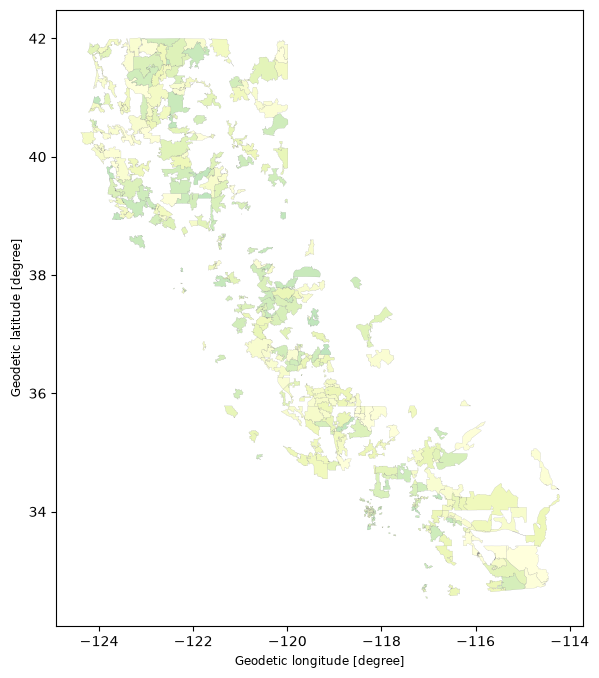

In [32]:
ca_shapefile_2021.plot(
    column='B19013_001E',  
    figsize=(10, 8),
    cmap='YlGnBu',          
    legend=True,            
    alpha=0.9,              
    edgecolor='grey',       
    linewidth=0.1
)